Here are the years available: 1900, 1910, 1920, 1930, 1940, 1950, 1954, 1959, 1964, 1969, 1974, 1978, 1982, 1987, 1992, 1997, 2002, 2007


Enter the year of your choice:  1910


You selected: 1910


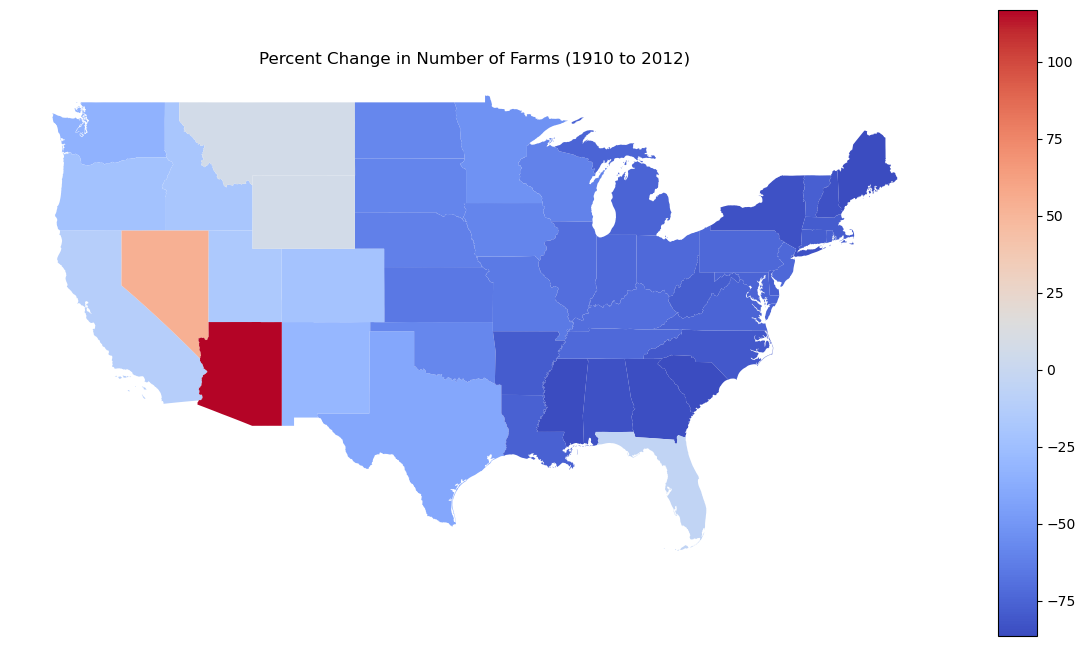

In [10]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
import os

# Using current directory as working directory base
BASE_DIR = os.getcwd()

###### GETTING DECADE FOR MAP ######

# List of options
options = ['1900','1910','1920','1930','1940','1950','1954','1959','1964',
           '1969','1974','1978','1982','1987','1992','1997','2002','2007']
print("Here are the years available:", ', '.join(options))

# Prompting input
year_selected = input("Enter the year of your choice: ")

# Checking whether input is a valid decade
if year_selected in options:
    print(f"You selected: {year_selected}")
    year = year_selected
    decade = float(year)
else:
    print("Invalid input. Please enter one of the listed years.")

###
# Loading data and state shapefiles
data_path = os.path.join(BASE_DIR, 'data', 'farms', 'farmdata.csv')
shapefile_path = os.path.join(BASE_DIR, 'data', 'cb_2018_us_state_5m')
population_data = pd.read_csv(data_path)
shapefile_data = gpd.read_file(shapefile_path)

# Fixing errors in state and population data
population_data['Areaname'] = population_data['Areaname'].str.strip()
shapefile_data['NAME'] = shapefile_data['NAME'].str.strip()

# Filtering to exclude territories, Alaska, and Hawaii
continental_states = shapefile_data[~shapefile_data['STUSPS'].isin(['AK', 'HI', 'PR', 'VI', 'MP', 'GU', 'AS'])]

# Merging the population data with the states shapefile
merged = continental_states.merge(population_data, left_on='NAME', right_on='Areaname', how='inner')

# Calculating percent change to 2012
merged['pct_change'] = ((merged['2012.0'] - merged[f'{decade}']) / merged[f'{decade}']) * 100

# Mapping data
fig, ax = plt.subplots(1, 1, figsize=(15, 10))
merged.plot(column='pct_change', cmap='coolwarm', legend=True, ax=ax)
plt.title(f'Percent Change in Number of Farms ({year} to 2012)')
plt.axis('off')
plt.show()